# K単体でのToeplitz+FFT+CG vs 直接Cholesky の比較

$Kz = y$ を解く2つの方法：

- **直接法**: $K$ を明示構築してCholesky $O(N^3)$
- **Toeplitz+FFT+CG**: $K$ は定常カーネル+均一グリッドで完全にToeplitz → 行列ベクトル積を FFT で $O(N \log N)$

イテレーション数が多くても，1回の積が $O(N^2) \to O(N \log N)$ になる効果を確認する。

In [7]:

using LinearAlgebra
using FFTW
using Random
using Printf
using Statistics
using Plots

# 未インストールの場合は一度だけ実行
# import Pkg
# Pkg.add(["FFTW", "Plots"])

Random.seed!(1234)
BLAS.set_num_threads(1)  # 比較条件を固定


In [8]:

# Toeplitz 行列の FFT 埋め込み
function toeplitz_fft_setup(c)
    n = length(c)
    p = vcat(c, 0.0, reverse(c[2:end]))
    return fft(p)
end

function toeplitz_fft_mul(p_fft, v, n)
    v_pad = vcat(v, zeros(n))
    z = ifft(p_fft .* fft(v_pad))
    return real.(z[1:n])
end

# CG 法
function cg_solve(matvec, b; tol=1e-8, maxiter=5000)
    x = zeros(length(b))
    r = b - matvec(x)
    p = copy(r)
    rr = dot(r, r)
    bnorm = norm(b)

    for iter in 1:maxiter
        Ap = matvec(p)
        denom = dot(p, Ap)

        if !isfinite(denom) || denom <= 0
            error("CG が正定値性または数値安定性の問題を検出しました")
        end

        a = rr / denom
        x .+= a .* p
        r .-= a .* Ap

        rr_new = dot(r, r)
        relres = sqrt(rr_new) / bnorm

        if relres <= tol
            return x, iter, relres, true
        end

        p .= r .+ (rr_new / rr) .* p
        rr = rr_new
    end

    relres = norm(b - matvec(x)) / bnorm
    return x, maxiter, relres, false
end


cg_solve (generic function with 1 method)

In [10]:

function benchmark_gp(n;
    dx=0.02, ell=0.15,
    sigma_f=1.0, sigma_n=0.10,
    tol=1e-8, maxiter=5000)

    x = collect(0:n-1) .* dx

    # Toeplitz 行列の第1列
    c = [sigma_f^2 *
         exp(-((i-1)*dx)^2 / (2ell^2))
         for i in 1:n]

    y = sin.(2pi .* x ./ 3) .+
        0.3 .* cos.(2pi .* x ./ 1.2) .+
        sigma_n .* randn(n)

    # ---- Dense Cholesky ----
    # 対角ノイズも含めて密行列を1回だけ構築
    A = [c[abs(i-j)+1] +
         (i == j ? sigma_n^2 : 0.0)
         for i in 1:n, j in 1:n]

    # ウォームアップ
    cholesky(Symmetric(A)) \ y

    GC.gc()
    t_dense = @elapsed begin
        alpha_dense = cholesky(Symmetric(A)) \ y
    end

    # ---- Toeplitz FFT + CG ----
    p_fft = toeplitz_fft_setup(c)

    matvec = v -> toeplitz_fft_mul(p_fft, v, n) .+
                  sigma_n^2 .* v

    # ウォームアップ
    cg_solve(matvec, y; tol=tol, maxiter=maxiter)

    GC.gc()
    t_cg = @elapsed begin
        alpha_cg, iters, cg_res, converged =
            cg_solve(matvec, y; tol=tol, maxiter=maxiter)
    end

    # 密行列を使わず FFT 演算で残差を検証
    fft_res = norm(matvec(alpha_cg) - y) / norm(y)

    # 密行列による解の残差も検証
    dense_res = norm(A * alpha_dense - y) / norm(y)

    return (
        n=n,
        dense_time=t_dense,
        cg_time=t_cg,
        iterations=iters,
        cg_residual=cg_res,
        fft_residual=fft_res,
        dense_residual=dense_res,
        converged=converged,
        rel_diff=norm(alpha_dense-alpha_cg) /
                 max(norm(alpha_dense), eps(Float64))
    )
end

# 指定されたデータサイズ
ns = [500, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000]

results = []

for n in ns
    @printf("\n===== n = %d =====\n", n)

    result = benchmark_gp(n)
    push!(results, result)

    @printf("Dense Cholesky : %.4f 秒\n", result.dense_time)
    @printf("Toeplitz + CG  : %.4f 秒\n", result.cg_time)
    @printf("CG 反復回数    : %d\n", result.iterations)
    @printf("CG 収束        : %s\n", result.converged)
    @printf("相対残差       : %.3e\n", result.fft_residual)
    @printf("解の相対誤差   : %.3e\n", result.rel_diff)

    # 次のサイズへ進む前に解放を促す
    GC.gc()
end




===== n = 500 =====
Dense Cholesky : 0.0013 秒
Toeplitz + CG  : 0.0045 秒
CG 反復回数    : 185
CG 収束        : true
相対残差       : 6.846e-09
解の相対誤差   : 2.289e-08

===== n = 1000 =====
Dense Cholesky : 0.0076 秒
Toeplitz + CG  : 0.0088 秒
CG 反復回数    : 272
CG 収束        : true
相対残差       : 6.306e-09
解の相対誤差   : 1.670e-08

===== n = 2000 =====
Dense Cholesky : 0.0591 秒
Toeplitz + CG  : 0.0218 秒
CG 反復回数    : 331
CG 収束        : true
相対残差       : 9.582e-09
解の相対誤差   : 1.369e-08

===== n = 3000 =====
Dense Cholesky : 0.1725 秒
Toeplitz + CG  : 0.0324 秒
CG 反復回数    : 351
CG 収束        : true
相対残差       : 9.432e-09
解の相対誤差   : 1.065e-08

===== n = 4000 =====
Dense Cholesky : 0.3983 秒
Toeplitz + CG  : 0.0591 秒
CG 反復回数    : 368
CG 収束        : true
相対残差       : 9.771e-09
解の相対誤差   : 8.866e-09

===== n = 5000 =====
Dense Cholesky : 0.7835 秒
Toeplitz + CG  : 0.0649 秒
CG 反復回数    : 368
CG 収束        : true
相対残差       : 9.636e-09
解の相対誤差   : 8.692e-09

===== n = 6000 =====
Dense Cholesky : 1.3012 秒
Toeplitz + CG  : 0.0793

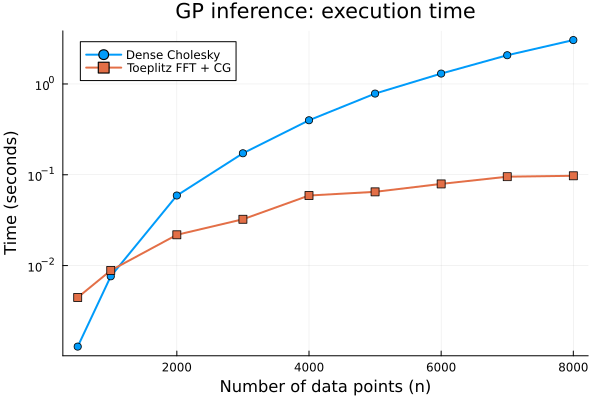

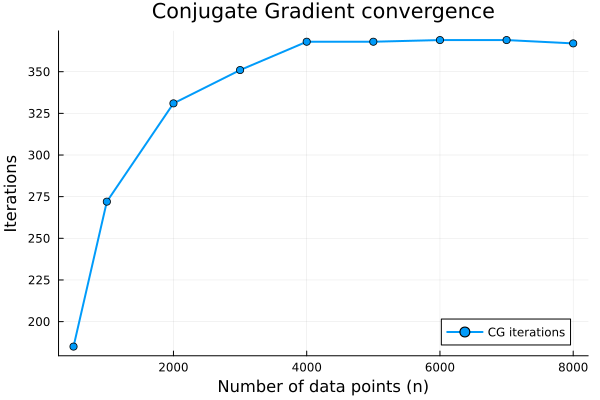

In [11]:

ns_result = [r.n for r in results]
t_dense = [r.dense_time for r in results]
t_cg = [r.cg_time for r in results]
iters = [r.iterations for r in results]

# グラフ1：実行時間
p1 = plot(
    ns_result, t_dense;
    marker=:circle, label="Dense Cholesky",
    xlabel="Number of data points (n)",
    ylabel="Time (seconds)",
    title="GP inference: execution time",
    yscale=:log10, linewidth=2
)

plot!(p1, ns_result, t_cg;
    marker=:square, label="Toeplitz FFT + CG",
    linewidth=2
)

# グラフ2：CG の反復回数
p2 = plot(
    ns_result, iters;
    marker=:circle, label="CG iterations",
    xlabel="Number of data points (n)",
    ylabel="Iterations",
    title="Conjugate Gradient convergence",
    linewidth=2
)

display(p1)
display(p2)



In [6]:

println("\n===== 最終比較 =====")

println(rpad("n", 8),
        rpad("Dense (s)", 16),
        rpad("Toeplitz (s)", 18),
        rpad("Speedup", 14),
        "CG iterations")

for r in results
    speedup = r.dense_time / r.cg_time

    @printf("%-8d %-16.5f %-18.5f %-14.3f %d\n",
        r.n, r.dense_time, r.cg_time,
        speedup, r.iterations)
end

# 計測値の傾向を確認
println("\nCG の全ケース収束: ",
        all(r.converged for r in results))



===== 最終比較 =====
n       Dense (s)       Toeplitz (s)      Speedup       CG iterations
500      0.00137          0.00426            0.321          185
1000     0.00823          0.01117            0.737          272
2000     0.05883          0.02350            2.503          331
3000     0.18359          0.03579            5.130          351
4000     0.42042          0.05082            8.273          368
5000     0.80428          0.06471            12.428         368
6000     1.36181          0.07464            18.246         369
7000     2.13226          0.09684            22.018         369
8000     3.20306          0.10197            31.412         367

CG の全ケース収束: true
